# Analysis 4: Is there a best time to publish?

**Business question.** Does the day and hour a video is published affect how well it does?

**What this data can and cannot answer.** The data only contains videos that trended. It cannot say whether publishing at a given time makes a video more likely to trend, because the videos that did not trend are missing. Time to trend is also not usable here: analysis 1 showed it depends on when the daily list is captured. What the data can answer is: **among videos that trended, do those published at some times reach more people?**

**Method.** Outcome: peak views over the trending run, on a log scale. Upload day and hour are in each country's local time (India IST, UK London time, US Eastern time). Only completed runs are used. Effects are shown first raw, then after controlling for category and for channel strength: the channel's average log peak views on its other trending videos, a stand-in for audience size, which the data does not record. Significance is tested with F-tests and the size of each effect is reported as partial eta squared (the share of remaining variance it explains).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

from streampulse.analysis import load_publish_slots
from streampulse.charts import COUNTRIES, COUNTRY_COLORS, COUNTRY_NAMES, DIVERGING_RAMP, apply_chart_style
from streampulse.database import connect

WEEKDAY_LABELS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MIN_VIDEOS_PER_SLOT = 30

apply_chart_style()
with connect() as connection:
    publish_slots = load_publish_slots(connection)

# Channels with a single trending video have no other videos to measure strength from.
modelled = publish_slots.dropna(subset=["channel_strength"]).copy()
print(f"{len(publish_slots):,} completed runs, {len(modelled):,} from channels with at least two trending videos "
      f"({100 * len(modelled) / len(publish_slots):.1f}%)")

172,401 completed runs, 164,616 from channels with at least two trending videos (95.5%)


## 1. Raw versus adjusted effects

For each country, residuals from two models give the percent difference in peak views for each upload slot compared with the country's average video:

- **Raw:** only the overall level (and, for India, the two data periods from analysis 3).
- **Adjusted:** also category and channel strength.

Slots with fewer than 30 videos are left blank.

In [2]:
def control_terms(country, adjusted):
    terms = ["1"]
    if country == "IN":
        terms.append("C(country_period)")
    if adjusted:
        terms += ["C(category)", "channel_strength"]
    return " + ".join(terms)


slot_residuals = []
for country in COUNTRIES:
    country_rows = modelled[modelled["country"] == country].copy()
    for label, adjusted in [("raw", False), ("adjusted", True)]:
        fitted_model = smf.ols(f"log_peak_views ~ {control_terms(country, adjusted)}", data=country_rows).fit()
        slot_residuals.append(country_rows.assign(model=label, residual=fitted_model.resid))
slot_residuals = pd.concat(slot_residuals)

slot_effects = (
    slot_residuals.groupby(["country", "model", "upload_weekday", "upload_hour"])["residual"]
    .agg(videos="size", mean_residual="mean")
    .reset_index()
)
slot_effects["pct_difference"] = 100 * (np.exp(slot_effects["mean_residual"]) - 1)
slot_effects.loc[slot_effects["videos"] < MIN_VIDEOS_PER_SLOT, "pct_difference"] = np.nan

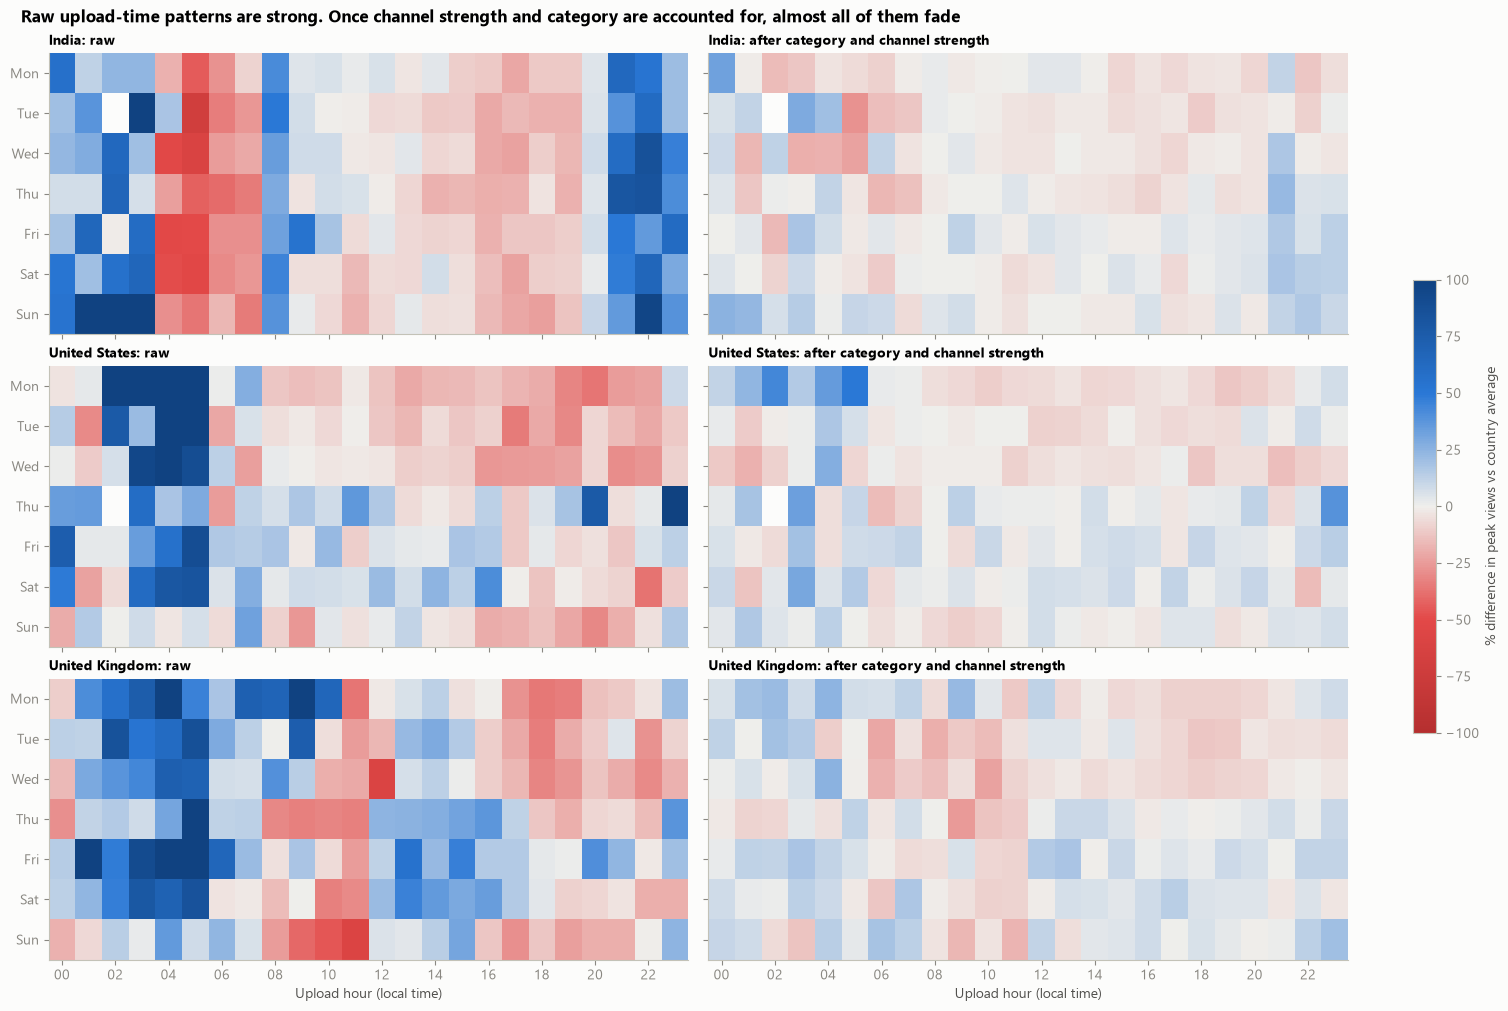

count   min   10%   90%    max
country model                                   
GB      adjusted  168.0 -25.3 -10.5  12.7   25.6
        raw       168.0 -59.0 -28.4  68.2  236.1
IN      adjusted  167.0 -27.5  -9.0  11.7   32.1
        raw       167.0 -70.1 -28.2  60.6  254.2
US      adjusted  167.0 -18.3  -8.4  12.5   49.3
        raw       167.0 -37.5 -23.0  60.2  325.9

In [3]:
color_limit = 100
fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=True, sharey=True, layout="constrained")
for row_axes, country in zip(axes, COUNTRIES):
    for ax, model_label in zip(row_axes, ["raw", "adjusted"]):
        grid = (
            slot_effects.query("country == @country and model == @model_label")
            .pivot(index="upload_weekday", columns="upload_hour", values="pct_difference")
            .reindex(index=range(1, 8), columns=range(24))
        )
        heatmap = ax.imshow(grid, cmap=DIVERGING_RAMP, vmin=-color_limit, vmax=color_limit, aspect="auto")
        ax.set_title(f"{COUNTRY_NAMES[country]}: {'raw' if model_label == 'raw' else 'after category and channel strength'}",
                     fontsize=10)
        ax.set_yticks(range(7), WEEKDAY_LABELS)
        ax.grid(False)
for ax in axes[-1]:
    ax.set_xticks(range(0, 24, 2), [f"{hour:02d}" for hour in range(0, 24, 2)])
    ax.set_xlabel("Upload hour (local time)")
fig.colorbar(heatmap, ax=axes, shrink=0.5, label="% difference in peak views vs country average")
fig.suptitle("Raw upload-time patterns are strong. Once channel strength and category are accounted for, almost all of them fade",
             x=0.01, ha="left", fontweight="bold")
plt.show()

(
    slot_effects.dropna(subset=["pct_difference"])
    .groupby(["country", "model"])["pct_difference"]
    .describe(percentiles=[0.1, 0.9])[["count", "min", "10%", "90%", "max"]]
    .round(1)
)

The range of the 168 slot cells exaggerates effects because each cell is a small sample. Hour of day pooled over weekdays has far more videos per point, so it shows the pattern more reliably.

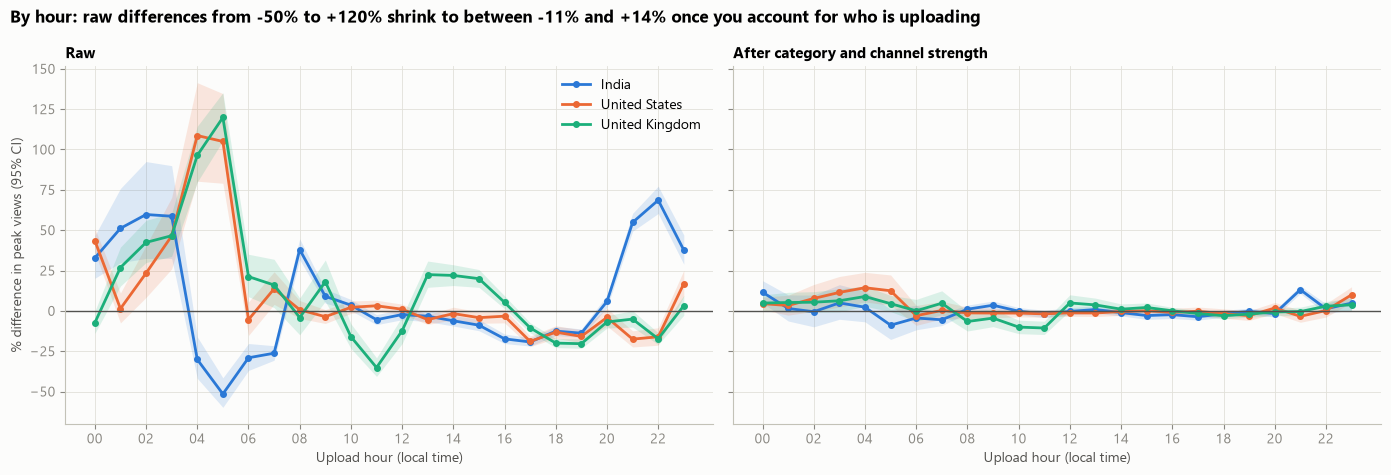

min    max
country model                
GB      adjusted -10.6    8.9
        raw      -35.1  119.8
IN      adjusted  -8.9   13.1
        raw      -51.5   68.6
US      adjusted  -3.4   14.3
        raw      -18.9  108.7

In [4]:
hour_effects = (
    slot_residuals.groupby(["country", "model", "upload_hour"])["residual"]
    .agg(videos="size", mean_residual="mean", standard_error=lambda residual: residual.std() / np.sqrt(len(residual)))
    .reset_index()
)
for column, source in [("pct_difference", 0), ("ci_low", -1.96), ("ci_high", 1.96)]:
    hour_effects[column] = 100 * (np.exp(hour_effects["mean_residual"] + source * hour_effects["standard_error"]) - 1)
hour_effects = hour_effects[hour_effects["videos"] >= MIN_VIDEOS_PER_SLOT]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, model_label in zip(axes, ["raw", "adjusted"]):
    for country in COUNTRIES:
        rows = hour_effects.query("country == @country and model == @model_label")
        ax.plot(rows["upload_hour"], rows["pct_difference"], marker="o", markersize=4,
                color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
        ax.fill_between(rows["upload_hour"], rows["ci_low"], rows["ci_high"], color=COUNTRY_COLORS[country],
                        alpha=0.15, linewidth=0)
    ax.axhline(0, color="#52514e", linewidth=1)
    ax.set_xticks(range(0, 24, 2), [f"{hour:02d}" for hour in range(0, 24, 2)])
    ax.set_xlabel("Upload hour (local time)")
    ax.set_title("Raw" if model_label == "raw" else "After category and channel strength", fontsize=11)
axes[0].set_ylabel("% difference in peak views (95% CI)")
axes[0].legend()
fig.suptitle("By hour: raw differences from -50% to +120% shrink to between -11% and +14% once you account for who is uploading",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

hour_effects.groupby(["country", "model"])["pct_difference"].agg(["min", "max"]).round(1)

## 2. Significance and size of the effects

Type II ANOVA F-tests for upload weekday and upload hour, without and with the controls. A third test asks whether the full 168-slot day-by-hour pattern adds anything once category and channel strength are in the model.

In [5]:
def partial_eta_squared(anova_table, term):
    return anova_table.loc[term, "sum_sq"] / (anova_table.loc[term, "sum_sq"] + anova_table.loc["Residual", "sum_sq"])


effect_rows = []
for country in COUNTRIES:
    country_rows = modelled[modelled["country"] == country].assign(
        upload_slot=lambda rows: rows["upload_weekday"].astype(str) + "_" + rows["upload_hour"].astype(str)
    )
    for label, adjusted in [("raw", False), ("adjusted", True)]:
        controls = control_terms(country, adjusted)
        fitted_model = smf.ols(f"log_peak_views ~ {controls} + C(upload_weekday) + C(upload_hour)", data=country_rows).fit()
        anova_table = sm.stats.anova_lm(fitted_model, typ=2)
        base_model = smf.ols(f"log_peak_views ~ {controls}", data=country_rows).fit()
        slot_model = smf.ols(f"log_peak_views ~ {controls} + C(upload_slot)", data=country_rows).fit()
        slot_f, slot_p, _ = slot_model.compare_f_test(base_model)
        effect_rows.append({
            "country": country,
            "model": label,
            "r_squared": fitted_model.rsquared,
            "weekday_partial_eta2": partial_eta_squared(anova_table, "C(upload_weekday)"),
            "weekday_p": anova_table.loc["C(upload_weekday)", "PR(>F)"],
            "hour_partial_eta2": partial_eta_squared(anova_table, "C(upload_hour)"),
            "hour_p": anova_table.loc["C(upload_hour)", "PR(>F)"],
            "slot_partial_eta2": (base_model.ssr - slot_model.ssr) / base_model.ssr,
            "slot_p": slot_p,
            "channel_strength_partial_eta2": (
                partial_eta_squared(anova_table, "channel_strength") if adjusted else np.nan
            ),
        })

effect_sizes = pd.DataFrame(effect_rows).set_index(["country", "model"])
effect_sizes.style.format({
    "r_squared": "{:.3f}", "weekday_partial_eta2": "{:.4f}", "hour_partial_eta2": "{:.4f}",
    "slot_partial_eta2": "{:.4f}", "weekday_p": "{:.1g}", "hour_p": "{:.1g}", "slot_p": "{:.1g}",
    "channel_strength_partial_eta2": "{:.3f}",
}, na_rep="")

## Finding

**There is no universal best time to publish. Upload-time patterns in trending videos mostly reflect which channels upload when.**

- **Raw patterns look large.** Compared with a country's average trending video, peak views range from about 50% lower (India, 05:00 IST) to about 120% higher (UK, 05:00, which is midnight US Eastern time) by upload hour. The full day-by-hour slot explains 3.2% (India) to 6.2% (UK) of the variation in peak views.
- **Most of it is the channel, not the clock.** Adding channel strength and category raises R-squared from 0.03 to 0.05 to between 0.59 and 0.68. Channel strength alone explains 55% to 63% of the remaining variation, over 200 times as much as upload hour (0.22% to 0.28%). After the controls, hour effects stay between -11% and +14%, and the full slot pattern explains 0.6% to 1.2%.
- **Significant, but small.** The adjusted effects are still statistically significant (F-test p below 1e-9 in every country), because tens of thousands of videos per country can detect very small effects. In practical terms they are minor.
- **The one pattern that survives** is that overnight uploads (00:00 to 05:00 local) still do about 5% to 14% better in the US and UK. These slots hold scheduled big releases, such as Friday-midnight music, which likely draw more views than the channel's usual video. That is a release-event effect more than a time-slot effect.

**Business answer.** Who is uploading matters far more than when. A channel should publish when its own audience is active; this data gives no evidence that a particular slot makes a trending video bigger.

**Limitations**

- Only trending videos are in the data, so this cannot show whether a slot changes the chance of trending.
- Channel strength is estimated from the channel's other trending videos, not subscriber counts; 4.5% of runs come from channels with a single trending video and are left out of the adjusted models.
- US local time uses Eastern time for the whole country.
- This is observational. Remaining effects can still come from things not measured, like planned launches.